# GraphDiffusionPipeline visualization

This notebook loads the run at `results/graph_pipeline/graph_pipeline_benchmark/20260714_212749`, inspects training behavior, reconstructs the saved `GraphDiffusionPipelineDecoder`, compares one-step and multi-step diffusion predictions, and visualizes pose graphs over CrowdPose images.

The notebook uses the repository convention:

- model coordinates: canonical `(x, y) ∈ [-1, 1]`
- displayed/evaluated coordinates: pixel `(x, y)`
- boxes: `(cx, cy, width, height)` in canonical model space or `(x, y, width, height)` in pixel space
- edges: the 14-joint CrowdPose skeleton

## 1. Load pose-graph data and dependencies

The run contains the Hydra configuration, CSV/TensorBoard logs, checkpoints, and test results. The cells below keep all paths relative to the repository root so the notebook can be moved without changing the experiment data.

In [2]:
from __future__ import annotations

import json
import math
import random
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from PIL import Image
from scipy.optimize import linear_sum_assignment
from omegaconf import OmegaConf

REPO_ROOT = Path.cwd().resolve()
if REPO_ROOT.name == "notebook":
    REPO_ROOT = REPO_ROOT.parent
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

RUN_DIR = REPO_ROOT / "results/graph_pipeline/graph_pipeline_benchmark/20260714_212749"
CONFIG_PATH = RUN_DIR / ".hydra/config.yaml"
CHECKPOINT_DIR = RUN_DIR / "checkpoints"
METRICS_PATH = RUN_DIR / "csv_logs/metrics.csv"
TEST_RESULTS_PATH = RUN_DIR / "test_results.json"

sns.set_theme(style="whitegrid", context="notebook")
torch.set_grad_enabled(False)

print(f"Repository: {REPO_ROOT}")
print(f"Run:        {RUN_DIR}")
print(f"Config:     {CONFIG_PATH.exists()}")
print(f"Metrics:    {METRICS_PATH.exists()}")
print(f"Checkpoints: {[p.name for p in CHECKPOINT_DIR.glob('*.ckpt')]}")

Repository: /home/gasparyanartur/dev/pose-graph-diff
Run:        /home/gasparyanartur/dev/pose-graph-diff/results/graph_pipeline/graph_pipeline_benchmark/20260714_212749
Config:     True
Metrics:    True
Checkpoints: ['epoch039-kpt_AP.ckpt', 'last.ckpt']


## 2. Define pose and edge representations

A pose graph is represented as a set of pose nodes, where each node contains a box, 14 keypoints, and an objectness score. The graph edges are the fixed CrowdPose anatomical connections. The helper functions below keep conversions and plotting independent from the model.

In [12]:
def make_prediction_graph(
    prediction: dict[str, torch.Tensor], image_hw: torch.Tensor, item_index: int = 0,
) -> PoseGraph:
    """Convert decoder output for one image into a pixel-space PoseGraph."""
    boxes = prediction["pred_boxes"][item_index].detach().cpu().float().numpy()
    centers = prediction["pred_boxes"][item_index, ..., :2].detach().cpu().float()
    joints_rel = prediction["pred_joints_rel"][item_index].detach().cpu().float()
    joints_abs = centers.unsqueeze(-2) + joints_rel
    img_h, img_w = image_hw.detach().cpu().float().tolist()
    image_wh = torch.tensor([[img_w, img_h]], dtype=joints_abs.dtype)
    joints_pixel = canonical_to_pixel(joints_abs[None], image_wh)[0].numpy()
    boxes_pixel = cxcywh_to_xyxy_pixel(boxes, (img_w, img_h))
    scores = torch.sigmoid(prediction["obj_logits"][item_index]).detach().cpu().float().numpy()
    return PoseGraph(boxes_pixel, joints_pixel, scores, "prediction")


print(f"CrowdPose joints: {JOINT_NAMES}")
print(f"Skeleton edges: {len(EDGE_LIST)} directed edges")

CrowdPose joints: ['left_shoulder', 'right_shoulder', 'left_elbow', 'right_elbow', 'left_wrist', 'right_wrist', 'left_hip', 'right_hip', 'left_knee', 'right_knee', 'left_ankle', 'right_ankle', 'head', 'neck']
Skeleton edges: 42 directed edges


## 3. Parse graphs from the repository

First inspect the saved experiment artifacts. The checkpoint selection prefers the best AP checkpoint and falls back to `last.ckpt`. The run configuration is the source of truth for reconstructing the exact model and data settings.

In [4]:
if not CONFIG_PATH.exists():
    raise FileNotFoundError(f"Missing saved Hydra config: {CONFIG_PATH}")

run_cfg = OmegaConf.load(CONFIG_PATH)
metrics = pd.read_csv(METRICS_PATH) if METRICS_PATH.exists() else pd.DataFrame()
metrics = metrics.apply(pd.to_numeric, errors="ignore")

if TEST_RESULTS_PATH.exists():
    test_results = json.loads(TEST_RESULTS_PATH.read_text())
else:
    test_results = {}

checkpoint_candidates = sorted(CHECKPOINT_DIR.glob("*.ckpt"))
best_checkpoint = CHECKPOINT_DIR / "epoch039-kpt_AP.ckpt"
if not best_checkpoint.exists():
    best_checkpoint = CHECKPOINT_DIR / "last.ckpt"
if not best_checkpoint.exists() and checkpoint_candidates:
    best_checkpoint = checkpoint_candidates[-1]

print(OmegaConf.to_yaml(run_cfg))
print(f"Metrics rows: {len(metrics)}")
print(f"Selected checkpoint: {best_checkpoint if best_checkpoint.exists() else 'none'}")
print("Test results:", test_results.get("metrics", {}))

backbone:
  _target_: src.features.CRadioV3BFeatureExtractorConfig
  frozen: true
decoder:
  _target_: src.decoders.diffusion.graph_pipeline.GraphDiffusionPipelineDecoderConfig
  num_slots: 20
  num_keypoints: 14
  dim: 256
  num_heads: 8
  num_trunk_blocks: 3
  num_joint_blocks: 2
  time_dim: 256
  ffn_mult: 4.0
  image_token_dim: 768
  spatial_feat_dim: 768
  dim_vis: 128
  dim_edge: 64
  num_refiner_layers: 3
  fourier_box_bands: 16
  fourier_box_scale: 1000.0
  fourier_joint_bands: 16
  fourier_joint_scale: 1000.0
  fourier_sigma_bands: 16
  fourier_sigma_scale: 1.0
  sigma_log_offset: 0.0001
  pe_scale: 1000.0
  dropout: 0.1
training_module:
  _target_: src.training.graph_pipeline_module.GraphDiffusionPipelineModuleConfig
  lr: 0.0002
  weight_decay: 0.0001
  cosine_lr: true
  lr_warmup_epochs: 1
  lr_min_frac: 0.01
  max_epochs: 100
  seed: 42
  grad_clip: 1.0
  resume: null
  sigma_min: 0.002
  sigma_max: 10.0
  rho: 7.0
  num_inference_steps: 5
  sigma_p_mean: -1.2
  sigma_p_st

/tmp/ipykernel_125400/2114864073.py:6: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  metrics = metrics.apply(pd.to_numeric, errors="ignore")


In [7]:
from src.data.data_config import DataConfig
from src.decoders.diffusion.graph_pipeline import GraphDiffusionPipelineDecoderConfig
from src.features import BaseFeatureExtractorConfig
from src.training.graph_pipeline_module import GraphDiffusionPipelineModuleConfig

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
module = None
backbone = None
data_module = None
checkpoint = None

try:
    backbone_cfg = BaseFeatureExtractorConfig.from_hydra_config(run_cfg.backbone)
    decoder_cfg = GraphDiffusionPipelineDecoderConfig.from_hydra_config(run_cfg.decoder)
    train_cfg = GraphDiffusionPipelineModuleConfig.from_hydra_config(run_cfg.training_module)
    data_cfg = DataConfig.from_hydra_config(run_cfg.data)

    # RADIO is frozen. Its pretrained weights are loaded by the extractor;
    # the training checkpoint contains the trainable decoder weights.
    backbone = backbone_cfg.build()
    decoder_cfg.image_token_dim = backbone.out_channels
    decoder_cfg.spatial_feat_dim = backbone.out_channels
    decoder = decoder_cfg.build()
    data_module = data_cfg.build(pin_memory=DEVICE.type == "cuda")
    module = train_cfg.build(
        backbone=backbone,
        decoder=decoder,
        val_ann_file=str(data_module.val_ann_path),
        test_ann_file=str(data_module.test_ann_path),
    )

    if not best_checkpoint.exists():
        raise FileNotFoundError("No checkpoint found in the saved run directory.")
    checkpoint = torch.load(best_checkpoint, map_location="cpu", weights_only=False)
    state_dict = checkpoint["state_dict"]

    # Load only decoder parameters. Older checkpoints contain RADIO buffer
    # entries but not the internal frozen RADIO weights.
    decoder_state = {
        key.removeprefix("decoder."): value
        for key, value in state_dict.items()
        if key.startswith("decoder.")
    }
    missing, unexpected = decoder.load_state_dict(decoder_state, strict=False)
    if missing:
        warnings.warn(f"Missing decoder keys: {missing[:5]}")
    if unexpected:
        warnings.warn(f"Unexpected decoder keys: {unexpected[:5]}")

    module.to(DEVICE).eval()
    backbone.eval()
    print(f"Loaded epoch: {checkpoint.get('epoch', 'unknown')}")
    print(f"Global step:  {checkpoint.get('global_step', 'unknown')}")
    print(f"Loaded decoder tensors: {len(decoder_state)}")
except Exception as exc:
    warnings.warn(
        "Model reconstruction was skipped. Metrics and graph-only sections remain "
        f"usable. Original error: {type(exc).__name__}: {exc}"
    )
    module = None
    backbone = None

print(f"Using device: {DEVICE}")
print(f"Model available: {module is not None}")

Loading weights:   0%|          | 0/175 [00:00<?, ?it/s]

loading annotations into memory...
Done (t=0.06s)
creating index...
index created!
loading annotations into memory...
Done (t=0.06s)
creating index...
index created!
loading annotations into memory...
Done (t=0.42s)
creating index...
index created!
loading annotations into memory...
Done (t=0.42s)
creating index...
index created!
Loaded epoch: 39
Global step:  6240
Loaded decoder tensors: 224
Using device: cuda
Model available: True


In [10]:
def gt_graph_from_batch(batch: dict, item_index: int = 0) -> PoseGraph:
    """Build a pixel-space graph from one collated CrowdPose batch item."""
    img_h, img_w = batch["img_hw"][item_index].detach().cpu().float().tolist()
    keypoints = batch["gt_keypoints"][item_index].detach().cpu().float()
    boxes = batch["gt_boxes_pixel"][item_index].detach().cpu().float()
    mask = batch.get("gt_box_labeled", batch.get("person_mask"))[item_index].detach().cpu() > 0
    image_wh = torch.tensor([[img_w, img_h]], dtype=keypoints.dtype)
    keypoints_pixel = canonical_to_pixel(keypoints[None], image_wh)[0].numpy()
    boxes_xywh = boxes[mask].numpy()
    boxes_xyxy = np.column_stack([
        boxes_xywh[:, 0], boxes_xywh[:, 1],
        boxes_xywh[:, 0] + boxes_xywh[:, 2],
        boxes_xywh[:, 1] + boxes_xywh[:, 3],
    ])
    return PoseGraph(
        boxes_xyxy=boxes_xyxy,
        keypoints_xy=keypoints_pixel[mask.numpy()],
        scores=np.ones(len(boxes_xyxy), dtype=np.float32),
        source="ground truth",
    )


val_batch = None
if data_module is not None:
    data_module.setup("fit")
    raw_batch = next(iter(data_module.val_dataloader()))
    val_batch = data_module.on_after_batch_transfer(raw_batch, 0)
    val_batch = {key: value.to(DEVICE) if torch.is_tensor(value) else value
                 for key, value in val_batch.items()}
    print({key: tuple(value.shape) if torch.is_tensor(value) else type(value).__name__
           for key, value in val_batch.items()})
    print(f"Validation image: {val_batch['img_path'][0]}")
    print(f"Validation image id: {int(val_batch['image_id'][0])}")
else:
    print("Dataset/model unavailable; graph parsing will use manually supplied arrays only.")

{'gt_keypoints': (64, 12, 14, 2), 'gt_labeled': (64, 12, 14), 'gt_visible': (64, 12, 14), 'person_scale': (64, 12), 'person_mask': (64, 12), 'gt_boxes_pixel': (64, 12, 4), 'gt_box_labeled': (64, 12), 'img_hw': (64, 2), 'image_id': (64,), 'img_path': 'list', 'image': (64, 3, 128, 128), 'padding_mask': (64, 128, 128), 'gt_boxes_canon': (64, 12, 4)}
Validation image: /home/gasparyanartur/dev/pose-graph-diff/data/crowdpose/images/114203.jpg
Validation image id: 114203


## 4. Compare pose-graph nodes

Nodes are the person instances and their 14 joint coordinates. For each predicted slot, the notebook first matches it to a ground-truth person using a cost made from box centre distance, box size distance, and mean visible-joint distance. This is an analysis-only assignment; it does not alter the saved model or training loss.

In [13]:
def match_pose_graphs(gt: PoseGraph, pred: PoseGraph) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Return matched GT indices, prediction indices, and the cost matrix."""
    if len(gt.boxes_xyxy) == 0 or len(pred.boxes_xyxy) == 0:
        return np.empty(0, dtype=int), np.empty(0, dtype=int), np.empty((len(gt.boxes_xyxy), len(pred.boxes_xyxy)))
    gt_centres = (gt.boxes_xyxy[:, :2] + gt.boxes_xyxy[:, 2:]) / 2
    pred_centres = (pred.boxes_xyxy[:, :2] + pred.boxes_xyxy[:, 2:]) / 2
    centre_cost = np.linalg.norm(gt_centres[:, None] - pred_centres[None, :], axis=-1)
    gt_sizes = gt.boxes_xyxy[:, 2:] - gt.boxes_xyxy[:, :2]
    pred_sizes = pred.boxes_xyxy[:, 2:] - pred.boxes_xyxy[:, :2]
    size_cost = np.linalg.norm(gt_sizes[:, None] - pred_sizes[None, :], axis=-1)
    joint_cost = np.linalg.norm(
        gt.keypoints_xy[:, None] - pred.keypoints_xy[None], axis=-1
    ).mean(axis=-1)
    cost = centre_cost / 100.0 + size_cost / 100.0 + joint_cost / 100.0
    gt_idx, pred_idx = linear_sum_assignment(cost)
    return gt_idx, pred_idx, cost


def visible_joint_mask(batch: dict, item_index: int = 0) -> np.ndarray:
    labels = batch["gt_labeled"][item_index].detach().cpu().numpy()
    return labels > 0


predictions = {}
prediction_graphs = {}
gt_graph = None
matches = {}
if module is not None and val_batch is not None:
    with torch.inference_mode():
        predictions["one_step"] = module._sample_decoder(val_batch, num_steps=1)
        predictions["five_step"] = module._sample_decoder(val_batch, num_steps=5)
    image_hw = val_batch["img_hw"][0]
    prediction_graphs = {
        name: make_prediction_graph(prediction, image_hw)
        for name, prediction in predictions.items()
    }
    gt_graph = gt_graph_from_batch(val_batch)
    matches = {
        name: match_pose_graphs(gt_graph, graph)
        for name, graph in prediction_graphs.items()
    }
    print(f"GT persons: {len(gt_graph.boxes_xyxy)}")
    for name, graph in prediction_graphs.items():
        print(f"{name}: {len(graph.boxes_xyxy)} slots, score range={graph.scores.min():.3f}-{graph.scores.max():.3f}")
else:
    print("Prediction comparison skipped because model reconstruction or validation data was unavailable.")

GT persons: 3
one_step: 20 slots, score range=0.004-0.791
five_step: 20 slots, score range=0.004-0.800


## 5. Compare pose-graph edges

Edges connect the same joint types in every pose graph. For each matched person, an edge is represented by its directed bone vector and its length. This separates a global pose translation error from an anatomical-shape error.

In [14]:
def edge_features(keypoints_xy: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """Return directed edge vectors and lengths for [P, K, 2] keypoints."""
    src = np.array([edge[0] for edge in EDGE_LIST], dtype=int)
    dst = np.array([edge[1] for edge in EDGE_LIST], dtype=int)
    vectors = keypoints_xy[:, dst] - keypoints_xy[:, src]
    lengths = np.linalg.norm(vectors, axis=-1)
    return vectors, lengths


def compare_edges(gt: PoseGraph, pred: PoseGraph, gt_idx: np.ndarray, pred_idx: np.ndarray) -> pd.DataFrame:
    rows = []
    gt_vectors, gt_lengths = edge_features(gt.keypoints_xy)
    pred_vectors, pred_lengths = edge_features(pred.keypoints_xy)
    for person_number, (gi, pi) in enumerate(zip(gt_idx, pred_idx)):
        for edge_number, ((src, dst), gt_vec, pred_vec, gt_len, pred_len) in enumerate(
            zip(EDGE_LIST, gt_vectors[gi], pred_vectors[pi], gt_lengths[gi], pred_lengths[pi])
        ):
            rows.append({
                "person": person_number,
                "edge": edge_number,
                "source_joint": JOINT_NAMES[src],
                "target_joint": JOINT_NAMES[dst],
                "gt_vector_x": gt_vec[0], "gt_vector_y": gt_vec[1],
                "pred_vector_x": pred_vec[0], "pred_vector_y": pred_vec[1],
                "vector_error": float(np.linalg.norm(pred_vec - gt_vec)),
                "gt_length": gt_len,
                "pred_length": pred_len,
                "length_error": float(abs(pred_len - gt_len)),
            })
    return pd.DataFrame(rows)


edge_tables = {}
if gt_graph is not None:
    for name, graph in prediction_graphs.items():
        gt_idx, pred_idx, _ = matches[name]
        edge_tables[name] = compare_edges(gt_graph, graph, gt_idx, pred_idx)
        print(name, edge_tables[name].shape)
else:
    print("Edge comparison skipped because no prediction graph is available.")

one_step (126, 12)
five_step (126, 12)


## 6. Compute graph-difference metrics

The report includes node displacement, box centre/size errors, edge vector/length errors, and aggregate summaries. The training-log panel is kept separate so optimization behavior can be compared with qualitative graph quality.

In [15]:
def compare_nodes(gt: PoseGraph, pred: PoseGraph, gt_idx: np.ndarray, pred_idx: np.ndarray) -> pd.DataFrame:
    rows = []
    gt_centres = (gt.boxes_xyxy[:, :2] + gt.boxes_xyxy[:, 2:]) / 2
    pred_centres = (pred.boxes_xyxy[:, :2] + pred.boxes_xyxy[:, 2:]) / 2
    gt_sizes = gt.boxes_xyxy[:, 2:] - gt.boxes_xyxy[:, :2]
    pred_sizes = pred.boxes_xyxy[:, 2:] - pred.boxes_xyxy[:, :2]
    for person_number, (gi, pi) in enumerate(zip(gt_idx, pred_idx)):
        joint_errors = np.linalg.norm(pred.keypoints_xy[pi] - gt.keypoints_xy[gi], axis=-1)
        for joint_index, error in enumerate(joint_errors):
            rows.append({
                "person": person_number,
                "joint": joint_index,
                "joint_name": JOINT_NAMES[joint_index],
                "joint_error": float(error),
                "gt_x": gt.keypoints_xy[gi, joint_index, 0],
                "gt_y": gt.keypoints_xy[gi, joint_index, 1],
                "pred_x": pred.keypoints_xy[pi, joint_index, 0],
                "pred_y": pred.keypoints_xy[pi, joint_index, 1],
                "box_centre_error": float(np.linalg.norm(pred_centres[pi] - gt_centres[gi])),
                "box_width_error": float(abs(pred_sizes[pi, 0] - gt_sizes[gi, 0])),
                "box_height_error": float(abs(pred_sizes[pi, 1] - gt_sizes[gi, 1])),
                "prediction_score": float(pred.scores[pi]),
            })
    return pd.DataFrame(rows)


node_tables = {}
aggregate_rows = []
for name, graph in prediction_graphs.items():
    gt_idx, pred_idx, cost = matches[name]
    node_table = compare_nodes(gt_graph, graph, gt_idx, pred_idx)
    node_tables[name] = node_table
    edge_table = edge_tables[name]
    aggregate_rows.append({
        "inference": name,
        "matched_persons": len(gt_idx),
        "gt_persons": len(gt_graph.boxes_xyxy),
        "prediction_slots": len(graph.boxes_xyxy),
        "mean_joint_error_px": node_table["joint_error"].mean() if len(node_table) else np.nan,
        "median_joint_error_px": node_table["joint_error"].median() if len(node_table) else np.nan,
        "mean_edge_vector_error_px": edge_table["vector_error"].mean() if len(edge_table) else np.nan,
        "mean_edge_length_error_px": edge_table["length_error"].mean() if len(edge_table) else np.nan,
        "mean_box_centre_error_px": node_table["box_centre_error"].mean() if len(node_table) else np.nan,
    })

aggregate_metrics = pd.DataFrame(aggregate_rows)
if len(aggregate_metrics):
    display(aggregate_metrics)
    display(node_tables["five_step"].groupby("joint_name")["joint_error"].agg(["mean", "median"]).sort_values("mean", ascending=False))

,inference,matched_persons,gt_persons,prediction_slots,mean_joint_error_px,median_joint_error_px,mean_edge_vector_error_px,mean_edge_length_error_px,mean_box_centre_error_px
0,one_step,3,3,20,126.342721,119.023823,47.706915,35.911787,104.502533
1,five_step,3,3,20,127.622553,115.735096,48.510235,36.431762,109.820566


,mean,median
joint_name,,
left_ankle,287.861633,235.103745
left_knee,207.018499,165.881302
left_wrist,173.852844,180.828110
right_ankle,150.286306,170.216843
left_hip,136.684804,128.995361
right_knee,123.847537,147.624100
left_elbow,118.374880,138.299927
right_hip,110.964569,109.887268
left_shoulder,102.575049,121.169647


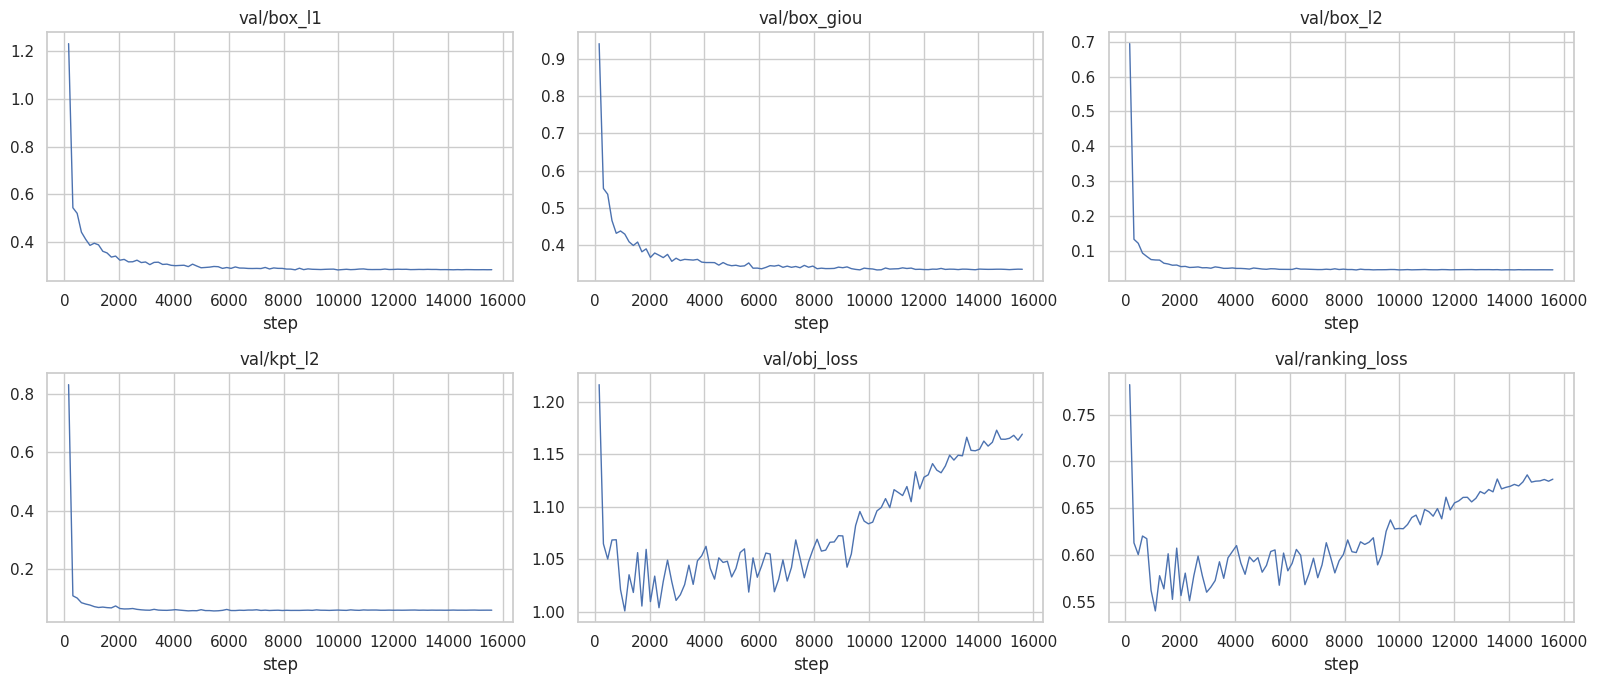

,epoch,step,ap-test/1-step/crowdpose/AP,ap-test/1-step/crowdpose/AP .5,ap-test/1-step/crowdpose/AP .75,ap-test/1-step/crowdpose/AP(E),ap-test/1-step/crowdpose/AP(H),ap-test/1-step/crowdpose/AP(M),ap-test/1-step/crowdpose/AR,ap-test/1-step/crowdpose/AR .5,...,ap-val/1-step/crowdpose/AR .75,ap-val/5-step/crowdpose/AP,ap-val/5-step/crowdpose/AP .5,ap-val/5-step/crowdpose/AP .75,ap-val/5-step/crowdpose/AP(E),ap-val/5-step/crowdpose/AP(H),ap-val/5-step/crowdpose/AP(M),ap-val/5-step/crowdpose/AR,ap-val/5-step/crowdpose/AR .5,ap-val/5-step/crowdpose/AR .75
59,9.0,1559,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.026435,0.011756,0.053353,0.000553,0.0151,0.0122,0.0105,0.078838,0.267458,0.026293
120,19.0,3119,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.042833,0.022484,0.096558,0.002504,0.0375,0.0240,0.0205,0.105344,0.322024,0.044247
181,29.0,4679,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.047781,0.021634,0.091176,0.003312,0.0310,0.0237,0.0192,0.110630,0.332344,0.048063
242,39.0,6239,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.052021,0.027112,0.108711,0.003343,0.0397,0.0306,0.0250,0.118999,0.348742,0.052163
304,49.0,7799,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.049194,0.024575,0.101845,0.004540,0.0350,0.0264,0.0263,0.112850,0.333192,0.050042
365,59.0,9359,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.051739,0.025521,0.105522,0.004071,0.0377,0.0282,0.0233,0.118660,0.349449,0.052304
426,69.0,10919,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.053294,0.023908,0.099137,0.003119,0.0356,0.0262,0.0213,0.116525,0.344077,0.054849
487,79.0,12479,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.054283,0.026017,0.108539,0.005112,0.0375,0.0293,0.0273,0.119395,0.350862,0.055131
548,89.0,14039,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.054990,0.024859,0.103711,0.003679,0.0375,0.0281,0.0233,0.119946,0.353407,0.053435
610,99.0,15599,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.055697,0.025194,0.105163,0.003959,0.0373,0.0284,0.0242,0.120144,0.352559,0.055131


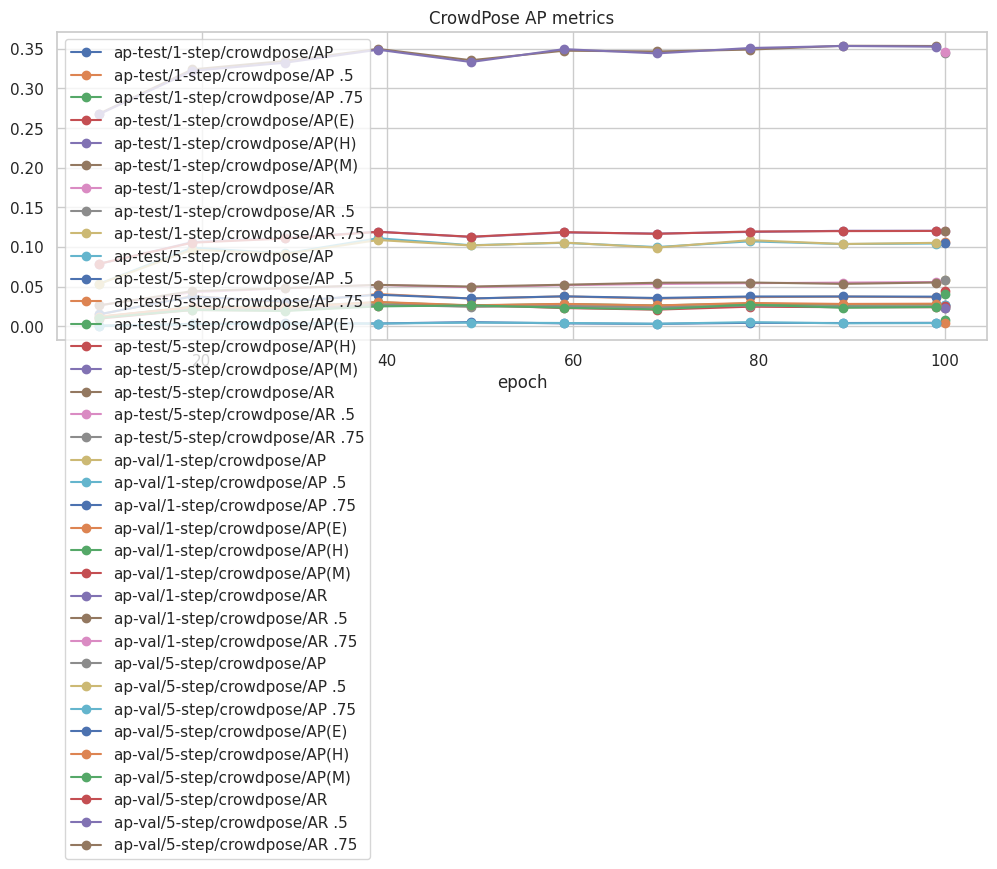

In [5]:
loss_columns = [
    "train/box_l1", "train/box_giou", "train/box_l2", "train/kpt_l2",
    "train/obj_loss", "train/ranking_loss", "val/box_l1", "val/box_giou",
    "val/box_l2", "val/kpt_l2", "val/obj_loss", "val/ranking_loss",
]
available_losses = [column for column in loss_columns if column in metrics.columns]
if available_losses:
    fig, axes = plt.subplots(math.ceil(len(available_losses) / 3), 3, figsize=(16, 3.5 * math.ceil(len(available_losses) / 3)), squeeze=False)
    for axis, column in zip(axes.flat, available_losses):
        series = metrics[["step", column]].dropna() if "step" in metrics else metrics[[column]].dropna()
        x = series["step"] if "step" in series else series.index
        axis.plot(x, series[column], linewidth=1)
        axis.set_title(column)
        axis.set_xlabel("step")
    for axis in axes.flat[len(available_losses):]:
        axis.axis("off")
    fig.tight_layout()
    plt.show()
else:
    print("No loss columns found in metrics.csv.")

ap_columns = [column for column in metrics.columns if "AP" in column or "ap" in column]
if ap_columns:
    ap_frame = metrics[[column for column in ["epoch", "step", *ap_columns] if column in metrics.columns]].dropna(how="all", subset=ap_columns)
    display(ap_frame.tail(20))
    ap_frame.set_index("epoch" if "epoch" in ap_frame else "step")[ap_columns].plot(marker="o", figsize=(12, 4), title="CrowdPose AP metrics")
    plt.show()
else:
    print("No AP columns found in metrics.csv.")

## 7. Visualize graph differences

The overlays show the original image, ground-truth graph, one-step prediction, and five-step prediction. Skeleton links are drawn using the shared `CANONICAL_EDGE_INDEX`, making differences attributable to coordinates rather than a changed topology.

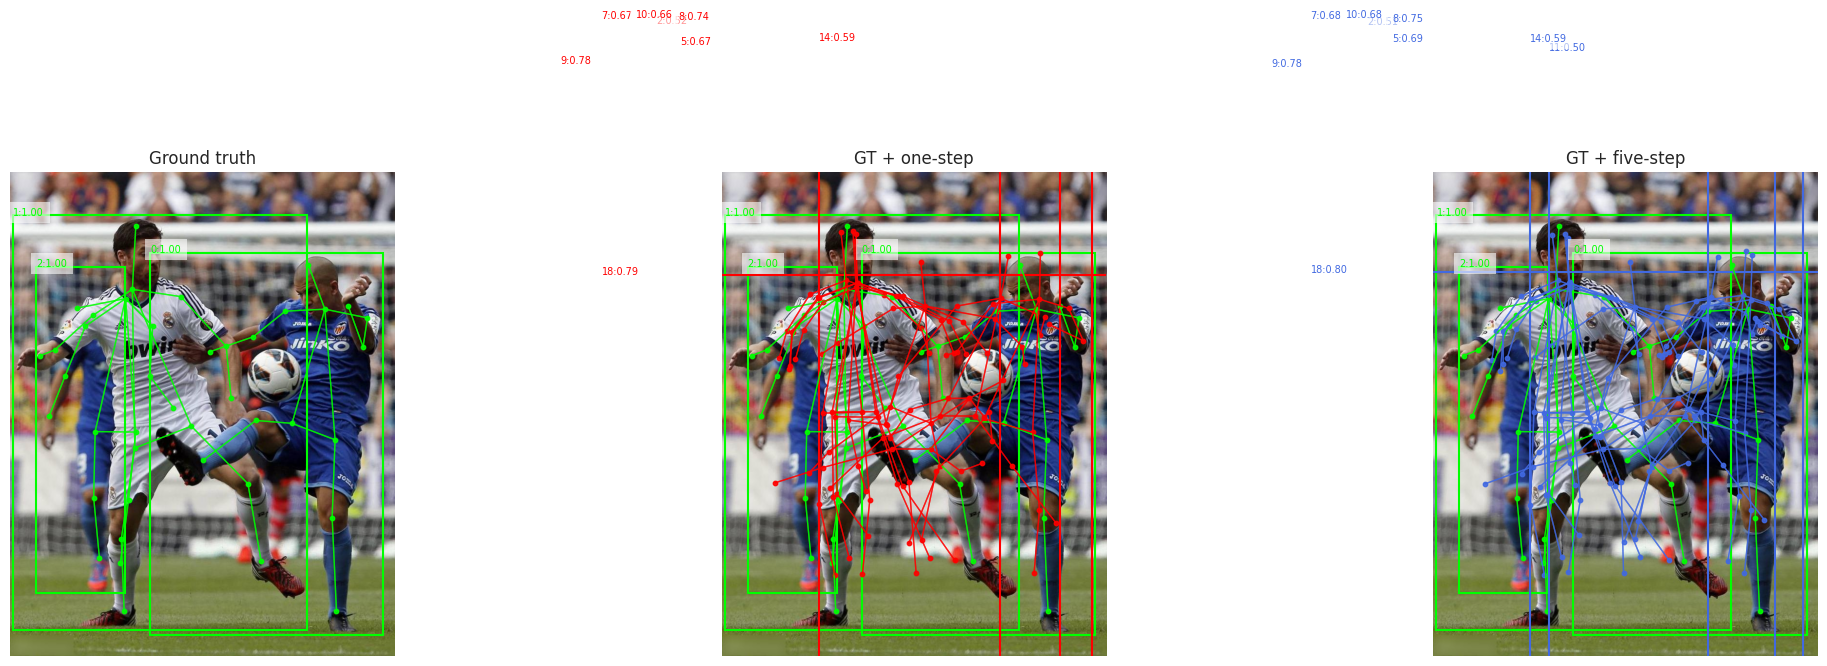

Saved overlay: /home/gasparyanartur/dev/pose-graph-diff/results/graph_pipeline/graph_pipeline_benchmark/20260714_212749/visualization/graph_overlays.png


In [20]:
def draw_pose_graph(axis, graph: PoseGraph, *, title: str, color: str, score_threshold: float = 0.0) -> None:
    axis.set_title(title)
    for person_index, (box, joints, score) in enumerate(zip(graph.boxes_xyxy, graph.keypoints_xy, graph.scores)):
        if score < score_threshold:
            continue
        x1, y1, x2, y2 = box
        axis.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, color=color, linewidth=1.5))
        axis.text(x1, y1, f"{person_index}:{score:.2f}", color=color, fontsize=7,
                  bbox={"facecolor": "white", "alpha": 0.6, "edgecolor": "none"})
        for src, dst in EDGE_LIST:
            axis.plot([joints[src, 0], joints[dst, 0]], [joints[src, 1], joints[dst, 1]],
                      color=color, alpha=0.65, linewidth=1)
        axis.scatter(joints[:, 0], joints[:, 1], s=10, color=color, alpha=0.9)


def show_graph_overlays(image_path: str, gt: PoseGraph, graphs: dict[str, PoseGraph]) -> None:
    image = np.asarray(Image.open(image_path).convert("RGB"))
    fig, axes = plt.subplots(1, 3, figsize=(20, 7))
    draw_pose_graph(axes[0], gt, title="Ground truth", color="lime", score_threshold=0.0)
    draw_pose_graph(axes[1], gt, title="GT + one-step", color="lime", score_threshold=0.0)
    draw_pose_graph(axes[1], graphs["one_step"], title="GT + one-step", color="red", score_threshold=0.5)
    draw_pose_graph(axes[2], gt, title="GT + five-step", color="lime", score_threshold=0.0)
    draw_pose_graph(axes[2], graphs["five_step"], title="GT + five-step", color="royalblue", score_threshold=0.5)
    for axis in axes:
        axis.imshow(image)
        axis.set_xlim(0, image.shape[1])
        axis.set_ylim(image.shape[0], 0)
        axis.axis("off")
    fig.tight_layout()
    overlay_path = RUN_DIR / "visualization" / "graph_overlays.png"
    overlay_path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(overlay_path, dpi=160, bbox_inches="tight")
    display(fig)
    plt.close(fig)
    print(f"Saved overlay: {overlay_path}")


if gt_graph is not None and val_batch is not None:
    show_graph_overlays(val_batch["img_path"][0], gt_graph, prediction_graphs)
else:
    print("Overlay skipped because no prediction graph is available.")

## 8. Export the difference report

Exports are written under the run directory, keeping the visualization outputs next to the checkpoint and metrics that produced them. Empty reports are still written when model reconstruction is unavailable, so downstream automation can distinguish “no predictions” from “not run”.

In [19]:
REPORT_DIR = RUN_DIR / "visualization"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

for name, table in node_tables.items():
    table.to_csv(REPORT_DIR / f"{name}_node_differences.csv", index=False)
for name, table in edge_tables.items():
    table.to_csv(REPORT_DIR / f"{name}_edge_differences.csv", index=False)
aggregate_metrics.to_csv(REPORT_DIR / "aggregate_graph_metrics.csv", index=False)

report_summary = {
    "run_dir": str(RUN_DIR),
    "checkpoint": str(best_checkpoint) if best_checkpoint.exists() else None,
    "config": str(CONFIG_PATH),
    "validation_image": val_batch["img_path"][0] if val_batch is not None else None,
    "validation_image_id": int(val_batch["image_id"][0]) if val_batch is not None else None,
    "inference_modes": list(prediction_graphs),
    "aggregate_metrics": aggregate_metrics.to_dict(orient="records"),
}
(REPORT_DIR / "graph_difference_report.json").write_text(json.dumps(report_summary, indent=2))
print(f"Wrote graph reports to {REPORT_DIR}")
print(sorted(path.name for path in REPORT_DIR.iterdir()))

Wrote graph reports to /home/gasparyanartur/dev/pose-graph-diff/results/graph_pipeline/graph_pipeline_benchmark/20260714_212749/visualization
['aggregate_graph_metrics.csv', 'five_step_edge_differences.csv', 'five_step_node_differences.csv', 'graph_difference_report.json', 'graph_overlays.png', 'one_step_edge_differences.csv', 'one_step_node_differences.csv']
